# Q2 · Notebook 3 — Fine-tuning RoBERTa (+ ablation)

**Model:** pre-trained `RobertaModel` (`roberta-base`, no pooler) → **masked mean pooling**
over all non-padded tokens of the last hidden layer → Dropout(0.1) → Linear(768 → 5).
The whole network is fine-tuned end-to-end.

**Training:** cross-entropy; AdamW (lr 2e-5, β = (0.9, 0.98), ε = 1e-6, weight decay 0.01
except biases/LayerNorm); linear warm-up over the first **6 %** of steps then linear decay
to 0; **mixed precision** (bf16 on Ampere+ GPUs, fp16 + loss scaling on T4/P100); batch 32
(use `grad_accum` if memory is short); 2 epochs, validation 4× per epoch, early stopping on
validation macro-F1 with the best checkpoint restored. Two seeds (42, 13).

**Ablation (chosen):** mean pooling vs **first-token (`<s>`) pooling**, everything else
identical. (The class-weighted-loss ablation would be uninformative here because the
dataset is perfectly balanced: 20 % per class.)

In [1]:
# --- Setup: work from the project root (the folder that contains src/) ---------------
# Colab: upload q2_rating_prediction.zip, then run
#   !unzip -q q2_rating_prediction.zip -d /content && %cd /content/q2_rating_prediction
# (or keep it on Google Drive so outputs survive a disconnect - see README).
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
print("project root:", ROOT)

import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, Markdown, display
pd.set_option("display.max_colwidth", 160)
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

project root: /content/q2_rating_prediction


torch 2.11.0+cu130 | GPU: Tesla T4


In [2]:
from src.train_roberta import RobertaConfig, run_roberta
SEEDS = [42, 13]
ROB = dict(model_name="roberta-base", max_len=256, batch_size=32, grad_accum=1,
           lr=2e-5, weight_decay=0.01, warmup_ratio=0.06, epochs=2,
           evals_per_epoch=4, patience=4, precision="auto")
# Out of GPU memory?  use batch_size=16, grad_accum=2 (same effective batch of 32).

import inspect
from src.models import RobertaRatingClassifier, masked_mean
print(inspect.getsource(masked_mean)); print(inspect.getsource(RobertaRatingClassifier.pool))

def masked_mean(hidden, attention_mask):
    """Average of the token vectors where attention_mask == 1 (padding excluded)."""
    m = attention_mask.unsqueeze(-1).to(hidden.dtype)
    return (hidden * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)

    def pool(self, hidden, attention_mask):
        hidden = hidden.float()  # pool in fp32 even under autocast
        if self.pooling == "mean":
            return masked_mean(hidden, attention_mask)
        return hidden[:, 0]



## Main model: mean pooling

In [3]:
for seed in SEEDS:
    run_roberta(RobertaConfig(seed=seed, pooling="mean", **ROB))

[09:34:45] device=cuda amp=torch.float16 run=roberta_mean_len256_seed42


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (25 outputs left out)

[10:22:29] epoch 1.50 | train loss 0.7242 F1 0.6835 | val loss 0.7791 F1 0.6629 acc 0.6634 MAE 0.3788 | *best*


[10:25:51] epoch 1.75 | train loss 0.7151 F1 0.6885 | val loss 0.7807 F1 0.6582 acc 0.6598 MAE 0.3826 | no gain 1/4


[10:29:09] epoch 2.00 | train loss 0.7109 F1 0.6904 | val loss 0.7783 F1 0.6606 acc 0.6628 MAE 0.3800 | no gain 2/4


[10:29:18] TEST  acc 0.6666 | macro-F1 0.6660 | MAE 0.3736  -> outputs/roberta_mean_len256_seed13


## Ablation: first-token (`<s>`) pooling

In [4]:
for seed in SEEDS:
    run_roberta(RobertaConfig(seed=seed, pooling="first", **ROB))

[10:29:18] device=cuda amp=torch.float16 run=roberta_first_len256_seed42


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[10:29:22] train=200,000 | 6,250 optimizer steps/epoch, total 12,500, warm-up 750 | effective batch 32


epoch 1:   0%|          | 0/6250 [00:00<?, ?it/s]

/content/q2_rating_prediction/src/engine.py:98: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


... (21 outputs left out)

[11:17:15] epoch 1.50 | train loss 0.7291 F1 0.6800 | val loss 0.7819 F1 0.6649 acc 0.6658 MAE 0.3768 | *best*


[11:20:37] epoch 1.75 | train loss 0.7190 F1 0.6869 | val loss 0.7821 F1 0.6641 acc 0.6654 MAE 0.3778 | no gain 1/4


[11:23:55] epoch 2.00 | train loss 0.7131 F1 0.6893 | val loss 0.7788 F1 0.6626 acc 0.6654 MAE 0.3774 | no gain 2/4


[11:24:04] TEST  acc 0.6674 | macro-F1 0.6664 | MAE 0.3734  -> outputs/roberta_first_len256_seed13


## Results and ablation

Choose between the variants with the **validation** columns; the test columns are only
reported (the test set never influences a decision).

,Variant,Seeds,Val macro-F1 (%),Val acc (%),Val MAE,Test macro-F1 (%),Test acc (%),Test MAE
0,"RoBERTa (mean pooling, len 256)",2,66.32 ± 0.05,66.44 ± 0.14,0.378 ± 0.002,66.70 ± 0.15,66.82 ± 0.23,0.373 ± 0.001
1,"RoBERTa (first pooling, len 256)",2,66.51 ± 0.04,66.69 ± 0.16,0.375 ± 0.003,66.50 ± 0.19,66.70 ± 0.06,0.375 ± 0.002


,Model,Seeds,Test accuracy (%),Test macro-F1 (%),Test MAE (stars),Val macro-F1 (%),Trainable params (M),Train time / seed (min),Best val epoch
0,"RoBERTa (mean pooling, len 256)","13, 42",66.82 ± 0.23,66.70 ± 0.15,0.373 ± 0.001,66.32 ± 0.05,124.1,26.9,"1.50, 2.00"
1,"RoBERTa (first pooling, len 256)","13, 42",66.70 ± 0.06,66.50 ± 0.19,0.375 ± 0.002,66.51 ± 0.04,124.1,27.2,"1.50, 1.50"


,Model,F1 1 star (%),F1 2 stars (%),F1 3 stars (%),F1 4 stars (%),F1 5 stars (%)
0,"RoBERTa (mean pooling, len 256)",74.41 ± 0.01,58.40 ± 0.49,57.67 ± 0.35,63.23 ± 0.52,79.81 ± 0.40
1,"RoBERTa (first pooling, len 256)",74.38 ± 0.10,58.22 ± 0.09,56.85 ± 0.24,62.91 ± 0.81,80.15 ± 0.30


,Model,Exact (%),Off by 1 star (%),Off by >=2 stars (%),Errors that are adjacent (%),4<->5 confusion rate (%),1<->5 confusions (count / 5000),MAE (stars)
0,"RoBERTa (mean pooling, len 256)",66.82 ± 0.23,29.62 ± 0.31,3.56 ± 0.08,89.27 ± 0.33,18.88 ± 0.25,6.5 ± 0.7,0.373 ± 0.001
1,"RoBERTa (first pooling, len 256)",66.70 ± 0.06,29.70 ± 0.03,3.60 ± 0.08,89.19 ± 0.24,18.75 ± 0.07,5.5 ± 0.7,0.375 ± 0.002


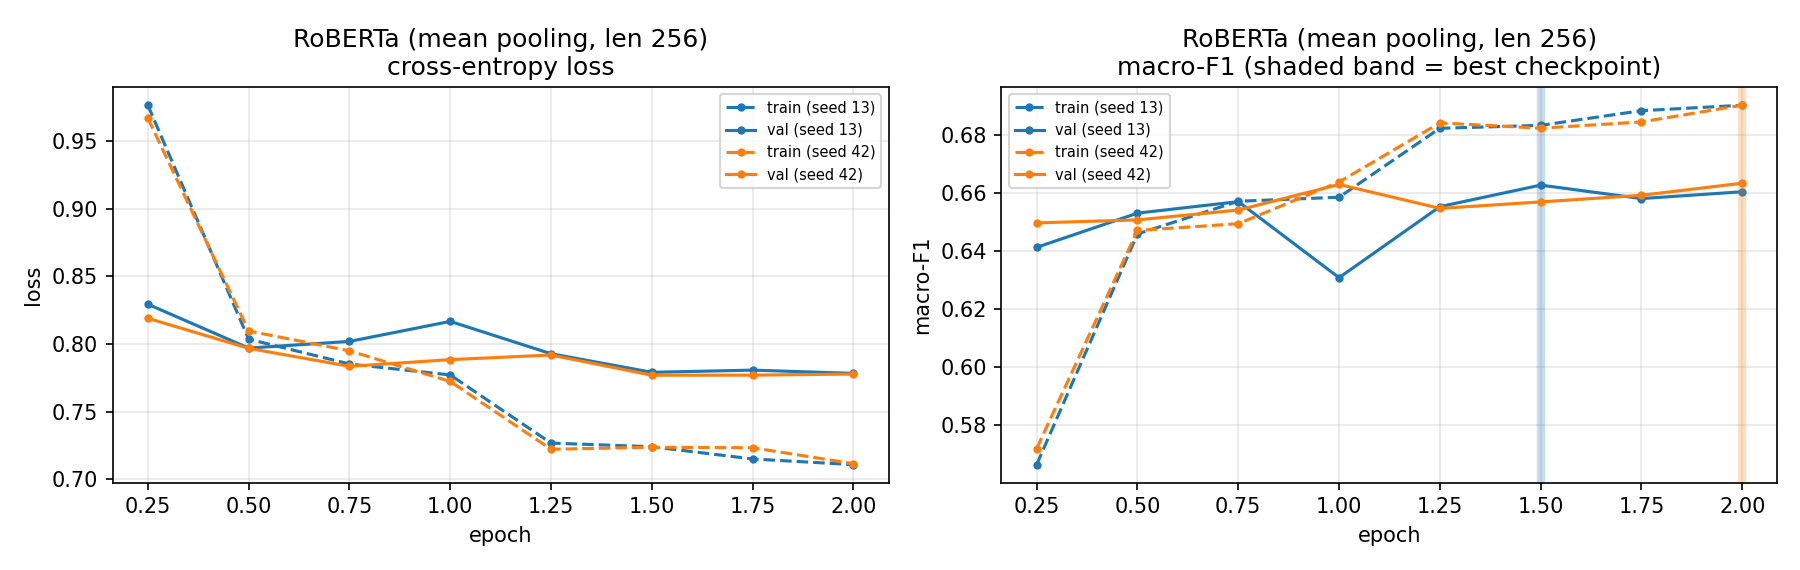

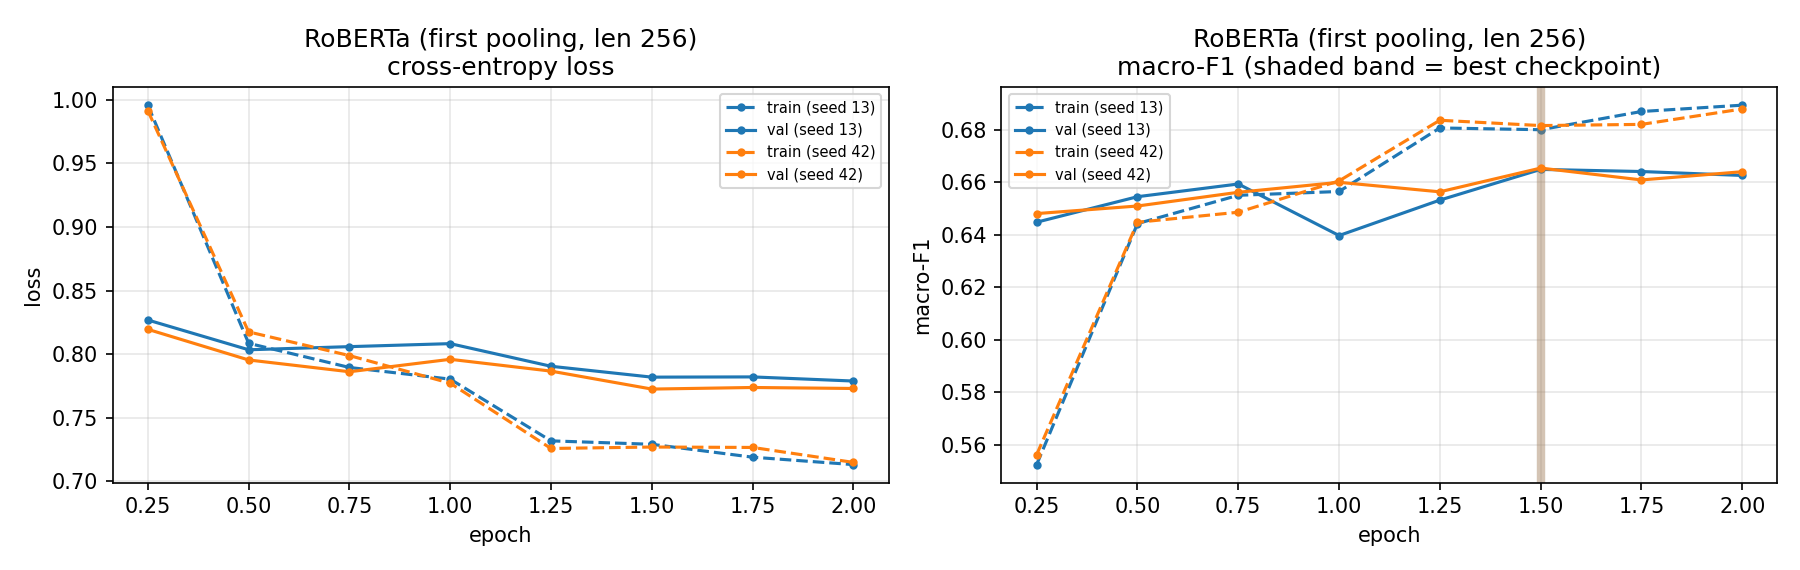

In [5]:
from src.analysis import load_runs, main_table, ablation_table, per_class_table, ordinal_table, plot_curves
Path("results").mkdir(exist_ok=True)
all_groups = load_runs("outputs")
rob_groups = {g: rs for g, rs in all_groups.items() if g.startswith("RoBERTa")}
display(ablation_table(rob_groups))
display(main_table(rob_groups))
display(per_class_table(rob_groups))
display(ordinal_table(rob_groups))
for p in plot_curves(rob_groups, "results")[1:]:
    display(Image(str(p)))

## Token-level importance for the transformer

Two views for the same review:

* **attention** — last-layer self-attention averaged over the 12 heads; for every word, the
  attention it *receives* averaged over all positions (sub-words summed into words). A large
  share usually goes to `<s>`/`</s>`; it is reported and the plot is renormalised over words.
* **occlusion** — delete one word at a time and record how much the probability of the
  predicted rating drops (red = supports the prediction, blue = argues against it).

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


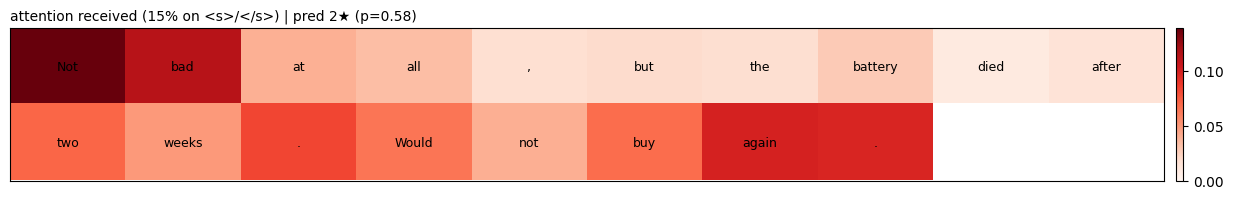

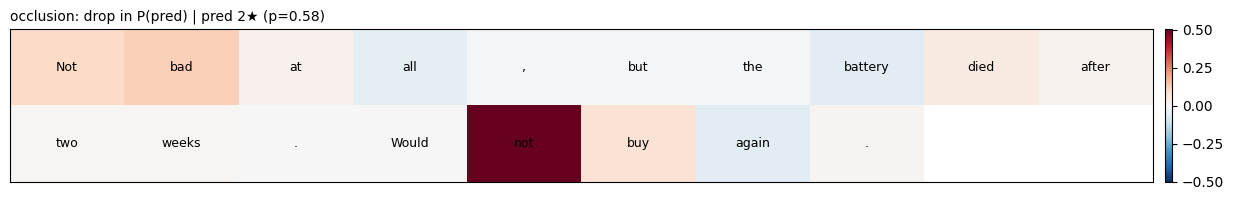

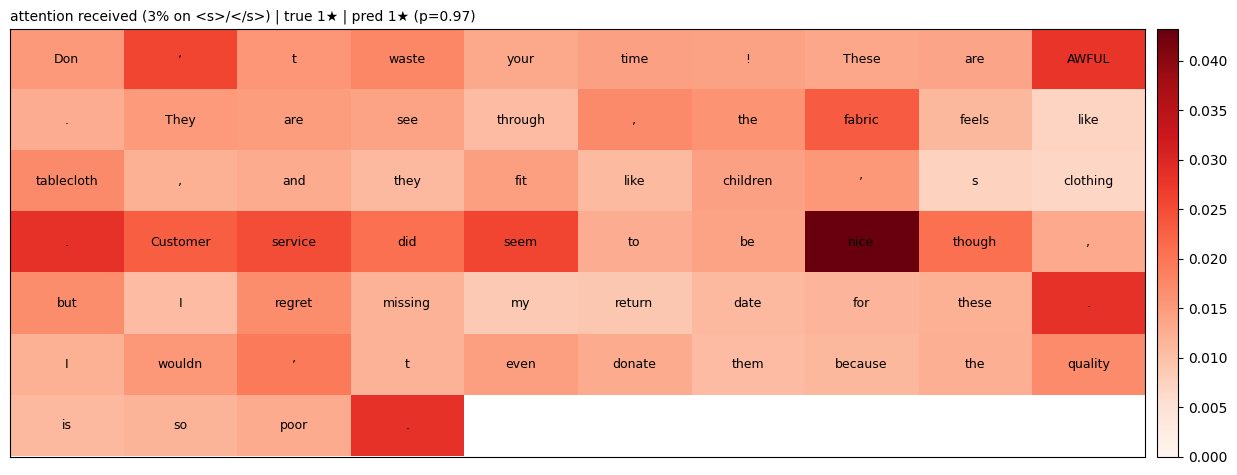

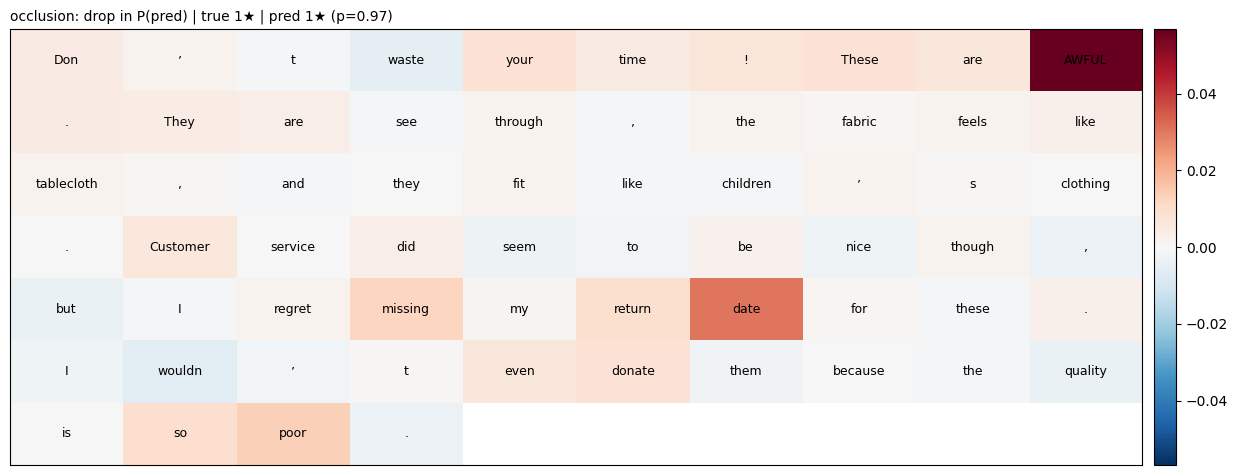

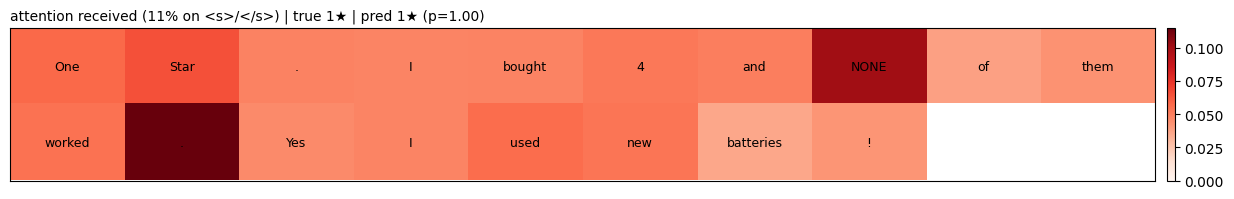

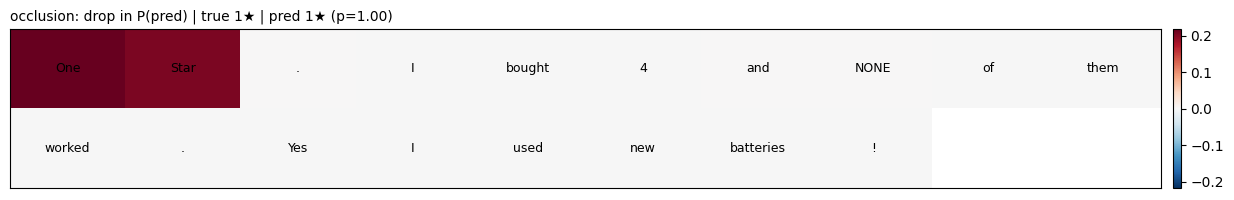

In [6]:
from src.explain import load_roberta, roberta_explain, plot_word_heatmap
from src.data import load_reviews
rmodel, rtok, rcfg = load_roberta(f"outputs/roberta_mean_len256_seed{SEEDS[0]}")
texts = [("Not bad at all, but the battery died after two weeks. Would not buy again.", None)]
test = load_reviews("data")[0]["test"]
texts += [(test[i]["text"], test[i]["label"]) for i in [0, 1]]
for text, label in texts:
    out = roberta_explain(rmodel, rtok, text, max_len=rcfg["max_len"])
    head = (f"true {label + 1}★ | " if label is not None else "") + f"pred {out['pred'] + 1}★ (p={out['probs'].max():.2f})"
    plot_word_heatmap(out["words"], out["attention"],
                      f"attention received ({out['special_token_attention_share']:.0%} on <s>/</s>) | {head}"); plt.show()
    plot_word_heatmap(out["words"], out["occlusion"], f"occlusion: drop in P(pred) | {head}", diverging=True); plt.show()